In [3]:
import numpy as np
import glob
import os

emb_dir = "/data/riccardop02/datasets/gso" 
model_dirs = sorted(
        d for d in os.listdir(emb_dir)
        if os.path.isdir(os.path.join(emb_dir, d))
    )

embeddings = []
shapes = []
for model_dir in model_dirs:
    model_path = os.path.join(emb_dir, model_dir)
    file = os.path.join(model_path, "embedding.npy")

    #load the .npy file 
    arr = np.load(file)
    embeddings.append(arr)
    shapes.append(arr.shape)

unique_shapes = set(shapes)
print(f"Oggetti trovati: {len(shapes)}, Shape uniche trovate: {unique_shapes}")


Oggetti trovati: 1030, Shape uniche trovate: {(512, 768)}


In [7]:
n_nan, n_inf, n_zero_vec = 0, 0, 0
bad_objects = {"nan": [], "inf": [], "zero": []}

for model_dir, arr in zip(model_dirs, embeddings):
    if np.isnan(arr).any():
        n_nan += 1
        bad_objects["nan"].append(model_dir)
    if np.isinf(arr).any():
        n_inf += 1
        bad_objects["inf"].append(model_dir)
    if np.allclose(arr, 0):
        n_zero_vec += 1
        bad_objects["zero"].append(model_dir)

print(f"Objects with NaN: {n_nan}/{len(embeddings)}")
print(f"Objects with Inf: {n_inf}/{len(embeddings)}")
print(f"Objects  zero: {n_zero_vec}/{len(embeddings)}")

for k, v in bad_objects.items():
    if v:
        print(f"Objects with {k}: {v}")

Objects with NaN: 0/1030
Objects with Inf: 0/1030
Objects  zero: 0/1030


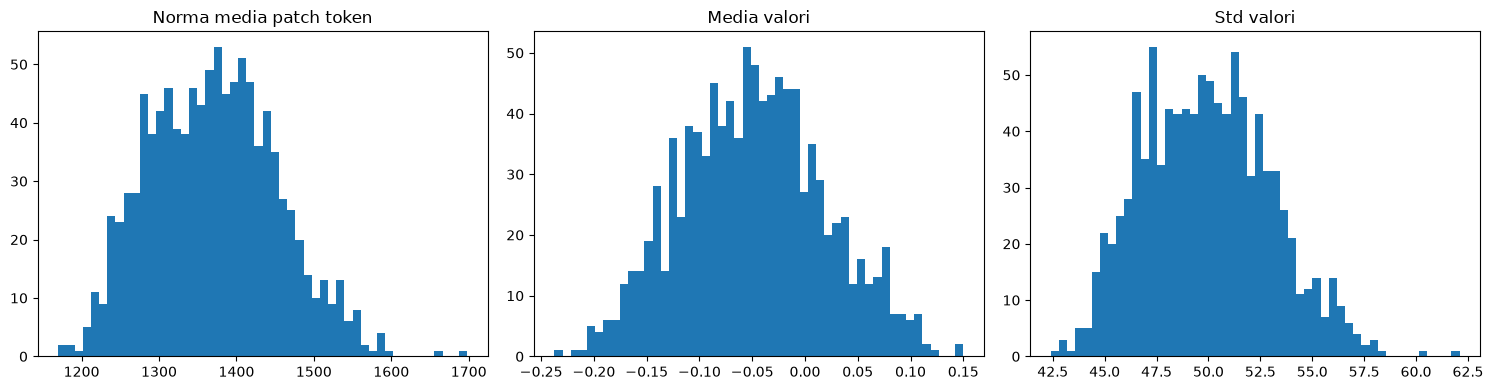

Norma:  min=1169.744, max=1697.839, media=1370.124


In [8]:
import matplotlib.pyplot as plt

norms = [np.linalg.norm(arr, axis=-1).mean() for arr in embeddings]
means = [arr.mean() for arr in embeddings]
stds = [arr.std() for arr in embeddings]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(norms, bins=50); axes[0].set_title("Norma media patch token")
axes[1].hist(means, bins=50); axes[1].set_title("Media valori")
axes[2].hist(stds, bins=50); axes[2].set_title("Std valori")
plt.tight_layout()
plt.show()

print(f"Norma:  min={min(norms):.3f}, max={max(norms):.3f}, media={np.mean(norms):.3f}")

In [9]:
global_embs = np.stack([arr.mean(axis=0) if arr.ndim > 1 else arr for arr in embeddings])
print("Shape embedding globali:", global_embs.shape)

norm_embs = global_embs / (np.linalg.norm(global_embs, axis=1, keepdims=True) + 1e-8)
sim_matrix = norm_embs @ norm_embs.T
np.fill_diagonal(sim_matrix, -1)

max_sim_idx = np.unravel_index(np.argmax(sim_matrix), sim_matrix.shape)
print(f"Similarità massima tra oggetti diversi: {sim_matrix[max_sim_idx]:.4f} "
      f"tra '{model_dirs[max_sim_idx[0]]}' e '{model_dirs[max_sim_idx[1]]}'")

n_suspect = (sim_matrix > 0.999).sum() // 2
print(f"Coppie con similarità > 0.999: {n_suspect}")

Shape embedding globali: (1030, 768)
Similarità massima tra oggetti diversi: 0.9994 tra 'Office_Depot_HP_564XL_Ink_Cartridge_Black_CN684WN' e 'Office_Depot_HP_932XL_Ink_Cartridge_Black_CN053A'
Coppie con similarità > 0.999: 28


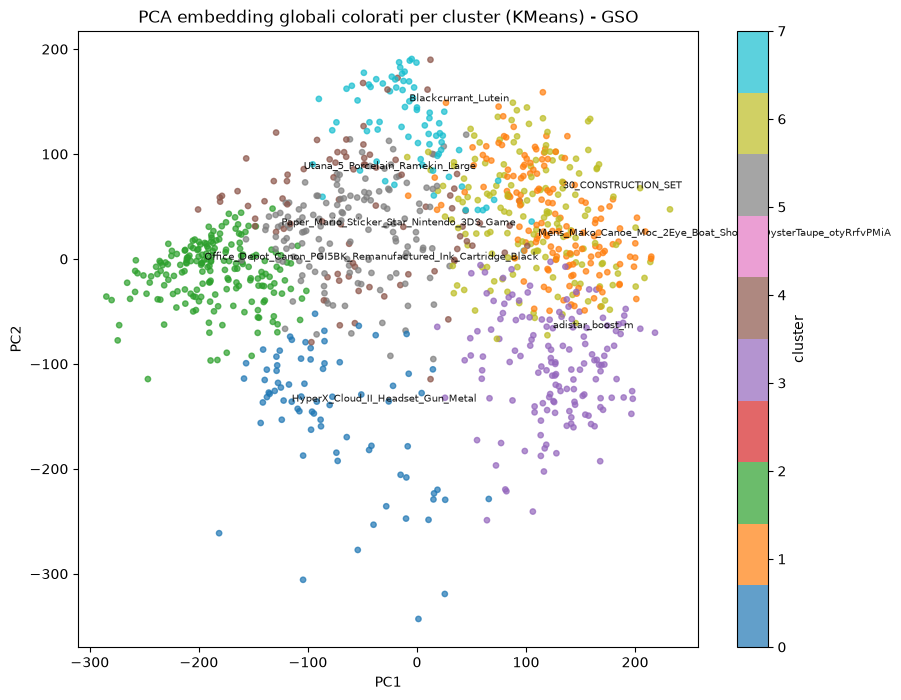

Dimensione cluster: [ 77 153 191 147  85 143 161  73]


In [12]:
from sklearn.cluster import KMeans

n_clusters = 8
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(global_embs)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(proj[:, 0], proj[:, 1], c=cluster_labels, cmap="tab10", s=15, alpha=0.7)
plt.title("PCA embedding globali colorati per cluster (KMeans) - GSO")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.colorbar(scatter, label="cluster")

# per ogni cluster, trovo il punto più vicino al centroide (rappresentativo)
# e lo annoto col nome file
for c in range(n_clusters):
    idx_in_cluster = np.where(cluster_labels == c)[0]
    centroid = global_embs[idx_in_cluster].mean(axis=0)
    dists = np.linalg.norm(global_embs[idx_in_cluster] - centroid, axis=1)
    representative_idx = idx_in_cluster[np.argmin(dists)]
    
    plt.annotate(model_dirs[representative_idx],
                 (proj[representative_idx, 0], proj[representative_idx, 1]),
                 fontsize=7, alpha=0.9)

plt.show()

print("Dimensione cluster:", np.bincount(cluster_labels))

In [13]:
from sklearn.cluster import KMeans

n_clusters = 10
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(global_embs)

print("Dimensione di ogni cluster:")
for c in range(n_clusters):
    print(f"  Cluster {c}: {np.sum(cluster_labels == c)} oggetti")

Dimensione di ogni cluster:
  Cluster 0: 109 oggetti
  Cluster 1: 111 oggetti
  Cluster 2: 74 oggetti
  Cluster 3: 130 oggetti
  Cluster 4: 81 oggetti
  Cluster 5: 129 oggetti
  Cluster 6: 31 oggetti
  Cluster 7: 85 oggetti
  Cluster 8: 121 oggetti
  Cluster 9: 159 oggetti


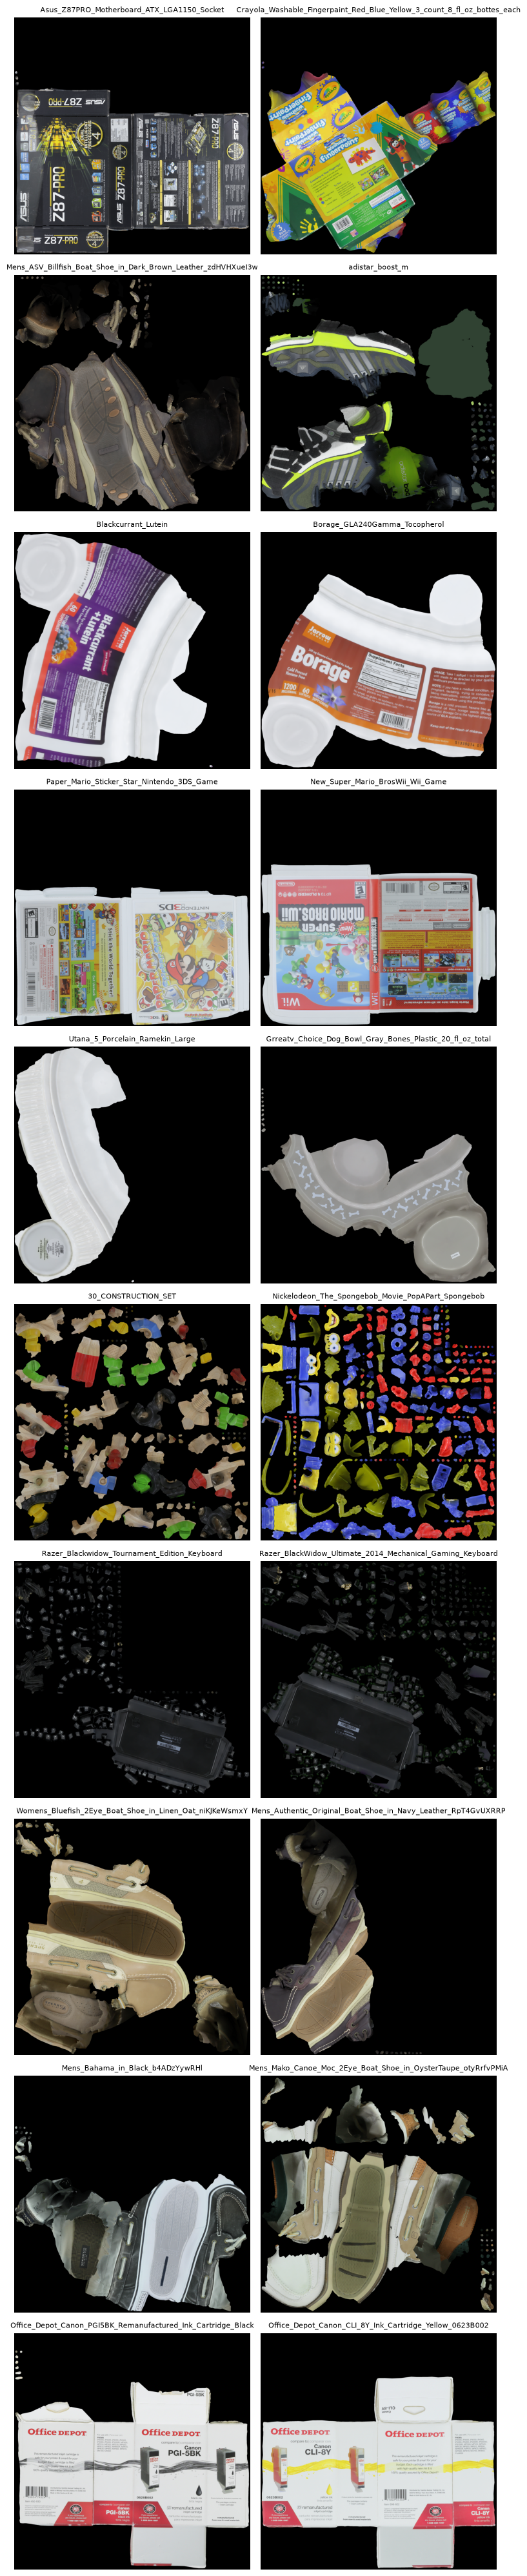

In [15]:
import matplotlib.image as mpimg

n_per_cluster = 2
fig, axes = plt.subplots(n_clusters, n_per_cluster, figsize=(4 * n_per_cluster, 4 * n_clusters))

for c in range(n_clusters):
    idx_in_cluster = np.where(cluster_labels == c)[0]
    centroid = global_embs[idx_in_cluster].mean(axis=0)
    dists = np.linalg.norm(global_embs[idx_in_cluster] - centroid, axis=1)
    chosen = idx_in_cluster[np.argsort(dists)[:n_per_cluster]]

    for j, idx in enumerate(chosen):
        ax = axes[c, j] if n_clusters > 1 else axes[j]
        img_path = os.path.join(emb_dir, model_dirs[idx], "materials/textures", "texture.png")
        img = mpimg.imread(img_path)
        ax.imshow(img)
        ax.set_title(model_dirs[idx], fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.show()